In [1]:
%pip install pandas numpy requests matplotlib seaborn biopython gemmi scikit-learn py3Dmol

   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.7 MB ? eta -:--:--
   --------------- ------------------------ 1.0/2.7 MB 3.7 MB/s eta 0:00:01
   ------------------------------ --------- 2.1/2.7 MB 4.1 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 3.9 MB/s  0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ----------------- ---------------------- 1.0/2.3 MB 7.2 MB/s eta 0:00:01
   ----------------------------------- ---- 2.1/2.3 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 2.3/2.3 MB 4.0 MB/s  0:00:00

   ------------- -------------------------- 1/3 [gemmi]
   ------------- -------------------------- 1/3 [gemmi]
   -------------------------- ------------- 2/3 [biopython]
   -------------------------- ------------- 2/3 [biopython]
   -------------------------- ------------- 2/3 [biopython]
   -------------------------- ------------- 2/3 [b

In [2]:
import sys, platform
import pandas as pd, numpy as np, requests, Bio, gemmi, sklearn

print("Python:", sys.version.split()[0])
print("OS:", platform.system())
print("pandas:", pd.__version__)
print("Biopython:", Bio.__version__)
print("gemmi:", gemmi.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.14.6
OS: Windows
pandas: 3.0.3
Biopython: 1.88
gemmi: 0.7.5
scikit-learn: 1.9.0


In [3]:
from pathlib import Path

BASE = Path.cwd() / "GeoVariant"

SUBDIRS = [
    "data/raw",          
    "data/processed",    
    "structures",       
    "results/tables",
    "results/figures",
    "notebooks",
]

for d in SUBDIRS:
    (BASE / d).mkdir(parents=True, exist_ok=True)

for p in sorted(BASE.rglob("*")):
    if p.is_dir():
        print(p.relative_to(BASE))

data
data\processed
data\raw
notebooks
results
results\figures
results\tables
structures


In [4]:
import json, datetime

config = {
    "project": "GeoVariant",
    "created": datetime.date.today().isoformat(),
    "genome_build": "GRCh38",
    "variant_scope": "missense SNV",
    "label_source": "ClinVar",
    "clinvar_release": "TODO: yükləyəndə tarixi yaz",
    "genes": [],  
    "notes": []
}

with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("config.json yaradıldı")

config.json yaradıldı


In [13]:
import requests, time
import pandas as pd

EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"

def clinvar_count(gene, extra_term):
    term = f'{gene}[gene] AND {extra_term}'
    r = requests.get(
        EUTILS,
        params={"db": "clinvar", "term": term, "retmode": "json", "retmax": 0},
        timeout=60,
    )
    r.raise_for_status()
    time.sleep(0.4)  
    return int(r.json()["esearchresult"]["count"])

candidates = ["TP53", "MLH1", "MSH2"]

rows = []
for g in candidates:
    missense = '"missense variant"[molecular consequence]'
    path = clinvar_count(g, f'{missense} AND "clinsig pathogenic"[Properties]')
    ben  = clinvar_count(g, f'{missense} AND "clinsig benign"[Properties]')
    rows.append({"gene": g, "pathogenic_missense": path, "benign_missense": ben})

df_counts = pd.DataFrame(rows)
print(df_counts)

   gene  pathogenic_missense  benign_missense
0  TP53                  210               38
1  MLH1                  101               22
2  MSH2                   88               48


In [14]:
uniprot_ids = {
    "TP53": "P04637", "MLH1": "P40692", "MSH2": "P43246",
}

def best_structures(uniprot_id):
    url = f"https://www.ebi.ac.uk/pdbe/api/mappings/best_structures/{uniprot_id}"
    r = requests.get(url, timeout=60)
    if r.status_code != 200:
        return []
    return r.json().get(uniprot_id, [])

pdb_rows = []
for gene, uid in uniprot_ids.items():
    hits = best_structures(uid)
    if not hits:
        pdb_rows.append({"gene": gene, "n_structures": 0})
        continue
    top = hits[0]
    pdb_rows.append({
        "gene": gene,
        "n_structures": len(hits),
        "best_pdb": top.get("pdb_id"),
        "resolution": top.get("resolution"),
        "unp_start": top.get("unp_start"),
        "unp_end": top.get("unp_end"),
        "coverage": top.get("coverage"),
    })
    time.sleep(0.3)

df_pdb = pd.DataFrame(pdb_rows)
print(df_pdb)

   gene  n_structures best_pdb  resolution  unp_start  unp_end  coverage
0  TP53           682     9r2q       3.200          1      393     1.000
1  MLH1            42     4p7a       2.300          1      347     0.459
2  MSH2            33     8rb1       2.085          1      934     1.000


In [15]:
summary = df_counts.merge(df_pdb, on="gene")
summary.to_csv(BASE / "results/tables/gene_candidates.csv", index=False)
summary

,gene,pathogenic_missense,benign_missense,n_structures,best_pdb,resolution,unp_start,unp_end,coverage
0,TP53,210,38,682,9r2q,3.200,1,393,1.000
1,MLH1,101,22,42,4p7a,2.300,1,347,0.459
2,MSH2,88,48,33,8rb1,2.085,1,934,1.000


In [16]:
config["genes"] = ["TP53", "PTEN", "MLH1"]   # öz seçiminlə əvəz et
config["notes"].append("Genlər ClinVar sayı və PDB əhatəsinə görə seçildi")

with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

In [ ]:
#FIRST STEP

In [17]:
config["genes"] = ["TP53", "MSH2", "MLH1"]
config["notes"].append("PTEN çıxarıldı (10 xoşxassəli), CFTR çıxarıldı (3 xoşxassəli), MSH2 əlavə edildi")

with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

CLINVAR_URL = "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/clinvar.vcf.gz"
GENES = set(config["genes"])
RAW_VCF = BASE / "data/raw/clinvar_selected_genes.vcf"
print("Genlər:", GENES)

Genlər: {'TP53', 'MLH1', 'MSH2'}


In [18]:
def gene_symbols(info):
    """INFO sütunundan gen adlarını çıxarır. Məs: 'GENEINFO=TP53:7157|WRAP53:55135' -> {'TP53','WRAP53'}"""
    for field in info.split(";"):
        if field.startswith("GENEINFO="):
            return {g.split(":")[0] for g in field[len("GENEINFO="):].split("|")}
    return set()

In [23]:
import gzip, requests

header_lines = []
n_total = 0
n_kept = 0

with requests.get(CLINVAR_URL, stream=True, timeout=120) as r:
    r.raise_for_status()
    with gzip.open(r.raw, "rt", encoding="utf-8") as fin, \
         open(RAW_VCF, "w", encoding="utf-8") as fout:

        for line in fin:
            if line.startswith("#"):          # başlıq sətirləri həmişə saxlanır
                fout.write(line)
                header_lines.append(line)
                continue

            n_total += 1
            if n_total % 500_000 == 0:
                print(f"{n_total:,} sətir oxundu, {n_kept} saxlandı...")

            cols = line.rstrip("\n").split("\t")
            if len(cols) < 8:
                continue

            if gene_symbols(cols[7]) & GENES:  # bizim genlərdən biri varmı?
                fout.write(line)
                n_kept += 1

print(f"\nBitdi. Ümumi variant: {n_total:,}, saxlanan: {n_kept:,}")
print("Fayl:", RAW_VCF)

500,000 sətir oxundu, 3621 saxlandı...
1,000,000 sətir oxundu, 14525 saxlandı...
1,500,000 sətir oxundu, 14525 saxlandı...
2,000,000 sətir oxundu, 14525 saxlandı...
2,500,000 sətir oxundu, 14525 saxlandı...
3,000,000 sətir oxundu, 14525 saxlandı...
3,500,000 sətir oxundu, 14525 saxlandı...
4,000,000 sətir oxundu, 18482 saxlandı...
4,500,000 sətir oxundu, 18482 saxlandı...

Bitdi. Ümumi variant: 4,620,758, saxlanan: 18,482
Fayl: C:\Users\Acer\GeoVariant\data\raw\clinvar_selected_genes.vcf


In [24]:
file_date = next((l.strip().split("=", 1)[1] for l in header_lines if l.startswith("##fileDate=")), "naməlum")
print("ClinVar fayl tarixi:", file_date)

config["clinvar_release"] = file_date
with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

ClinVar fayl tarixi: 2026-11-15


In [25]:
import pandas as pd

cols = ["CHROM", "POS", "ID", "REF", "ALT", "QUAL", "FILTER", "INFO"]
df = pd.read_csv(RAW_VCF, sep="\t", skiprows=len(header_lines), names=cols, dtype=str)

def parse_info(info):
    d = {}
    for item in info.split(";"):
        if "=" in item:
            k, v = item.split("=", 1)
            d[k] = v
    return d

info_df = df["INFO"].apply(parse_info).apply(pd.Series)

df["GENE"]       = df["INFO"].apply(lambda s: ",".join(sorted(gene_symbols(s) & GENES)))
df["CLNSIG"]     = info_df.get("CLNSIG")
df["CLNREVSTAT"] = info_df.get("CLNREVSTAT")
df["MC"]         = info_df.get("MC")

out_csv = BASE / "data/processed/variants_selected_genes_parsed.csv"
df[["CHROM","POS","ID","REF","ALT","GENE","CLNSIG","CLNREVSTAT","MC"]].to_csv(out_csv, index=False)

print(df.shape)
df[["CHROM","POS","REF","ALT","GENE","CLNSIG","CLNREVSTAT","MC"]].head(10)

(18482, 12)


,CHROM,POS,REF,ALT,GENE,CLNSIG,CLNREVSTAT,MC
0,2,47401746,GCTGTGATTACAGGCGCCCACCACTATGCCCGGTAATTTTTGTATT...,G,MSH2,Likely_pathogenic,"criteria_provided,_single_submitter",SO:0002153|genic_upstream_transcript_variant
1,2,47401746,GCTGTGATTACAGGCGCCCACCACTATGCCCGGTAATTTTTGTATT...,G,MSH2,Likely_pathogenic,"criteria_provided,_single_submitter",SO:0002153|genic_upstream_transcript_variant
2,2,47402579,G,T,MSH2,Benign,"criteria_provided,_single_submitter",NaN
3,2,47402759,T,G,MSH2,Benign,reviewed_by_expert_panel,NaN
4,2,47402787,C,T,MSH2,Likely_benign,"criteria_provided,_single_submitter",NaN
5,2,47402870,ACCCAGGGGCTT,A,MSH2,Uncertain_significance,"criteria_provided,_single_submitter",NaN
6,2,47402874,A,AG,MSH2,Uncertain_significance,"criteria_provided,_single_submitter",NaN
7,2,47402874,A,T,MSH2,Likely_benign,"criteria_provided,_single_submitter",NaN
8,2,47402874,AG,A,MSH2,Uncertain_significance,"criteria_provided,_single_submitter",NaN
9,2,47402875,G,A,MSH2,Uncertain_significance,"criteria_provided,_single_submitter",NaN


In [26]:
# 1) Hər gendə neçə variant var?
print(df["GENE"].value_counts(), "\n")

# 2) Xromosomlar düzgündürmü? (TP53 -> 17, MSH2 -> 2, MLH1 -> 3)
print(df.groupby("GENE")["CHROM"].unique(), "\n")

# 3) Klinik təsnifatların paylanması
print(df["CLNSIG"].value_counts().head(15), "\n")

# 4) Nəticə növləri (missense və s.)
print(df["MC"].str.split("|").str[-1].str.split(",").str[0].value_counts().head(10))

GENE
MSH2    8217
MLH1    6308
TP53    3957
Name: count, dtype: int64 

GENE
MLH1     [3]
MSH2     [2]
TP53    [17]
Name: CHROM, dtype: object 

CLNSIG
Uncertain_significance                                     5464
Pathogenic                                                 3788
Likely_benign                                              3293
Conflicting_classifications_of_pathogenicity               2522
Benign/Likely_benign                                       1344
Likely_pathogenic                                           798
Pathogenic/Likely_pathogenic                                574
Benign                                                      527
not_provided                                                 19
no_classification_for_the_single_variant                      3
no_classifications_from_unflagged_records                     1
drug_response                                                 1
Pathogenic/Likely_pathogenic/Pathogenic,_low_penetrance       1
Name: count, dty

In [ ]:
#STEP 2

In [27]:
import pandas as pd

IN_CSV = BASE / "data/processed/variants_selected_genes_parsed.csv"
v = pd.read_csv(IN_CSV, dtype=str)

funnel = [("Başlanğıc (bütün variantlar)", len(v))]
print("Başlanğıc:", len(v))

Başlanğıc: 18482


In [28]:
# 1) Missense
v = v[v["MC"].fillna("").str.contains("missense_variant")].copy()
funnel.append(("Missense", len(v)))

# 2) Tək nukleotid dəyişikliyi (REF və ALT hər biri 1 hərf)
v = v[(v["REF"].str.len() == 1) & (v["ALT"].str.len() == 1)].copy()
funnel.append(("Missense + SNV", len(v)))

print(funnel[-2:])

[('Missense', 7395), ('Missense + SNV', 7265)]


In [29]:
PATHOGENIC = {"Pathogenic", "Likely_pathogenic", "Pathogenic/Likely_pathogenic"}
BENIGN     = {"Benign", "Likely_benign", "Benign/Likely_benign"}

def make_label(x):
    if x in PATHOGENIC:
        return 1
    if x in BENIGN:
        return 0
    return None   # VUS, Conflicting, not_provided və s.

v["label"] = v["CLNSIG"].map(make_label)

print("Atılacaq (etiketsiz) variantların növləri:")
print(v.loc[v["label"].isna(), "CLNSIG"].value_counts(), "\n")

v = v[v["label"].notna()].copy()
v["label"] = v["label"].astype(int)
funnel.append(("Aydın etiketli (patogen/xoşxassəli)", len(v)))

Atılacaq (etiketsiz) variantların növləri:
CLNSIG
Uncertain_significance                                     4104
Conflicting_classifications_of_pathogenicity               1986
not_provided                                                  3
Pathogenic/Likely_pathogenic/Pathogenic,_low_penetrance       1
Name: count, dtype: int64 



In [30]:
def stars(s):
    if pd.isna(s): return 0
    if "practice_guideline" in s: return 4
    if "reviewed_by_expert_panel" in s: return 3
    if "criteria_provided,_multiple_submitters,_no_conflicts" in s: return 2
    if "criteria_provided,_single_submitter" in s: return 1
    return 0   # no_assertion_criteria_provided və s.

v["stars"] = v["CLNREVSTAT"].map(stars)

# Süzgəcdən əvvəl baxış: ulduz səviyyəsinə görə neçə variant var?
print(pd.crosstab(v["stars"], v["label"]))

label    0    1
stars          
0        3    8
1      359  105
2       64  268
3      129  220


In [31]:
for min_stars in [1, 2]:
    sub = v[v["stars"] >= min_stars]
    print(f"\n>= {min_stars} ulduz:")
    print(pd.crosstab(sub["GENE"], sub["label"]))


>= 1 ulduz:
label    0    1
GENE           
MLH1    43  194
MSH2   341  162
TP53   168  237

>= 2 ulduz:
label   0    1
GENE          
MLH1   34  143
MSH2   80  132
TP53   79  213


In [32]:
MIN_STARS = 1   # cədvəllərə baxandan sonra qərar ver

v = v[v["stars"] >= MIN_STARS].copy()
funnel.append((f"Keyfiyyət (≥{MIN_STARS} ulduz)", len(v)))

In [33]:
v = v.drop_duplicates(subset=["CHROM", "POS", "REF", "ALT"]).copy()
funnel.append(("Təkrarsız", len(v)))

# Eyni variant həm 0, həm 1 etiketi ala bilməz (yoxlama)
conflict = v.groupby(["CHROM", "POS", "REF", "ALT"])["label"].nunique().gt(1).sum()
print("Ziddiyyətli etiketli variant sayı (0 olmalıdır):", conflict)

Ziddiyyətli etiketli variant sayı (0 olmalıdır): 0



=== SÜZGƏC ZƏNCİRİ ===
Başlanğıc (bütün variantlar)                   18,482
Missense                                        7,395
Missense + SNV                                  7,265
Aydın etiketli (patogen/xoşxassəli)             1,156
Keyfiyyət (≥1 ulduz)                            1,145
Təkrarsız                                       1,145

=== GEN ÜZRƏ ===
      benign (0)  pathogenic (1)
GENE                            
MLH1          43             194
MSH2         341             162
TP53         168             237


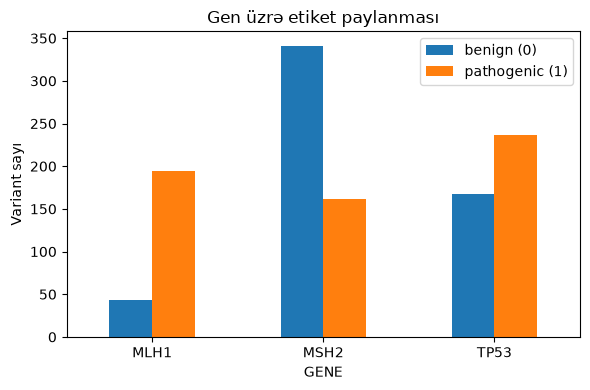

In [34]:
import matplotlib.pyplot as plt

# Süzgəc zənciri
print("\n=== SÜZGƏC ZƏNCİRİ ===")
for name, n in funnel:
    print(f"{name:45s} {n:>7,}")

# Gen üzrə saylar
summary = v.groupby(["GENE", "label"]).size().unstack(fill_value=0)
summary.columns = ["benign (0)", "pathogenic (1)"]
print("\n=== GEN ÜZRƏ ===")
print(summary)

# Qrafik
summary.plot(kind="bar", figsize=(6, 4))
plt.title("Gen üzrə etiket paylanması")
plt.ylabel("Variant sayı")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(BASE / "results/figures/label_distribution.png", dpi=200)
plt.show()

In [35]:
final_cols = ["CHROM", "POS", "REF", "ALT", "GENE", "CLNSIG", "CLNREVSTAT", "stars", "label"]
out_csv = BASE / "data/processed/variants_missense_labeled.csv"
v[final_cols].to_csv(out_csv, index=False)

summary.to_csv(BASE / "results/tables/label_counts_per_gene.csv")

config["notes"].append(
    f"Mərhələ 2: missense SNV, patogen/xoşxassəli etiketlər, VUS/ziddiyyətli atıldı, >= {MIN_STARS} ulduz"
)
with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Yadda saxlandı:", out_csv, "| cəmi:", len(v))

Yadda saxlandı: C:\Users\Acer\GeoVariant\data\processed\variants_missense_labeled.csv | cəmi: 1145


In [ ]:
#STEP3

In [36]:
import requests, time, json
import pandas as pd

v = pd.read_csv(BASE / "data/processed/variants_missense_labeled.csv", dtype={"CHROM": str})
v = v.reset_index(drop=True)
v["vid"] = "v" + v.index.astype(str)      # hər variant üçün unikal ad

VEP_URL = "https://rest.ensembl.org/vep/human/region"   # standart olaraq GRCh38
HEADERS = {"Content-Type": "application/json", "Accept": "application/json"}
PARAMS = {
    "canonical": 1,   # kanonik transkripti işarələ
    "mane": 1,        # MANE Select işarələ
    "hgvs": 1,        # p.Arg175His kimi yazılış
    "protein": 1,     # zülal ID-ləri
    "uniprot": 1,     # UniProt nömrəsi
    "sift": "b",      # SIFT skoru (baseline üçün)
    "polyphen": "b",  # PolyPhen skoru (baseline üçün)
}
print(len(v), "variant göndəriləcək")

1145 variant göndəriləcək


In [37]:
def vep_batch(rows):
    """Bir qrup variantı (maksimum 200) VEP-ə göndərir."""
    lines = [f"{r.CHROM} {r.POS} {r.vid} {r.REF} {r.ALT} . . ." for r in rows.itertuples()]
    for attempt in range(5):
        resp = requests.post(VEP_URL, headers=HEADERS, params=PARAMS,
                             data=json.dumps({"variants": lines}), timeout=180)
        if resp.status_code == 200:
            return resp.json()
        if resp.status_code == 429:                       # çox sorğu göndərmisən
            time.sleep(float(resp.headers.get("Retry-After", 2)) + 1)
            continue
        print("Xəta:", resp.status_code, resp.text[:300])
        time.sleep(3)
    raise RuntimeError("VEP cavab vermədi")

In [38]:
test = vep_batch(v.head(5))
print(len(test), "nəticə gəldi\n")

# İlk nəticənin quruluşuna bax
r0 = test[0]
print("id:", r0.get("id"))
for t in r0.get("transcript_consequences", [])[:3]:
    print({k: t.get(k) for k in ["gene_symbol", "transcript_id", "consequence_terms",
                                 "amino_acids", "protein_start", "mane_select", "canonical", "swissprot"]})

5 nəticə gəldi

id: v0
{'gene_symbol': 'MSH2', 'transcript_id': 'ENST00000233146', 'consequence_terms': ['missense_variant'], 'amino_acids': 'A/T', 'protein_start': 2, 'mane_select': 'NM_000251.3', 'canonical': 1, 'swissprot': ['P43246.254']}
{'gene_symbol': 'MSH2', 'transcript_id': 'ENST00000406134', 'consequence_terms': ['missense_variant'], 'amino_acids': 'A/T', 'protein_start': 2, 'mane_select': None, 'canonical': None, 'swissprot': None}
{'gene_symbol': 'MSH2', 'transcript_id': 'ENST00000543555', 'consequence_terms': ['intron_variant'], 'amino_acids': None, 'protein_start': None, 'mane_select': None, 'canonical': None, 'swissprot': ['P43246.254']}


In [39]:
BATCH = 150
all_results = []

for start in range(0, len(v), BATCH):
    chunk = v.iloc[start:start + BATCH]
    all_results.extend(vep_batch(chunk))
    print(f"{min(start + BATCH, len(v))}/{len(v)} göndərildi")
    time.sleep(1)

# Xam cavabı saxla (təkrarlanabilirlik üçün)
with open(BASE / "data/raw/vep_raw.json", "w", encoding="utf-8") as f:
    json.dump(all_results, f)
print("Cəmi cavab:", len(all_results))

150/1145 göndərildi
300/1145 göndərildi
450/1145 göndərildi
600/1145 göndərildi
750/1145 göndərildi
900/1145 göndərildi
1050/1145 göndərildi
1145/1145 göndərildi
Cəmi cavab: 1145


In [40]:
def pick_transcript(res):
    """MANE Select (yoxdursa kanonik) transkriptdə missense nəticəsini qaytarır."""
    tcs = [t for t in res.get("transcript_consequences", []) if t.get("gene_symbol") in GENES]
    preferred = [t for t in tcs if t.get("mane_select")] or [t for t in tcs if t.get("canonical") == 1]
    for t in preferred:
        if "missense_variant" in t.get("consequence_terms", []):
            return t
    return None

rows = []
for res in all_results:
    t = pick_transcript(res)
    if t is None:
        rows.append({"vid": res.get("id"), "ok": False})
        continue
    aa = t.get("amino_acids", "")                 # məsələn "R/H"
    wt, mut = (aa.split("/") + [None, None])[:2]
    sp = t.get("swissprot") or []
    rows.append({
        "vid": res.get("id"),
        "ok": True,
        "transcript_id": t.get("transcript_id"),
        "protein_id": t.get("protein_id"),
        "uniprot": sp[0].split(".")[0] if sp else None,
        "aa_pos": t.get("protein_start"),
        "aa_pos_end": t.get("protein_end"),
        "wt_aa": wt,
        "mut_aa": mut,
        "hgvsp": t.get("hgvsp"),
        "sift_pred": t.get("sift_prediction"),
        "sift_score": t.get("sift_score"),
        "polyphen_pred": t.get("polyphen_prediction"),
        "polyphen_score": t.get("polyphen_score"),
    })

ann = pd.DataFrame(rows)
print("Missense kimi təsdiqləndi:", ann["ok"].sum(), "/", len(ann))

Missense kimi təsdiqləndi: 1072 / 1145


In [41]:
m = v.merge(ann, on="vid", how="left")

n0 = len(m)
m = m[m["ok"] == True].copy()
print(f"MANE/kanonik transkriptdə missense olmayan atıldı: {n0 - len(m)}")

# Yalnız bir qalıq dəyişən və aydın amin turşuları
m = m[(m["aa_pos"] == m["aa_pos_end"]) & m["wt_aa"].str.len().eq(1) & m["mut_aa"].str.len().eq(1)].copy()
m["aa_pos"] = m["aa_pos"].astype(int)
print("Yekun variant sayı:", len(m))

MANE/kanonik transkriptdə missense olmayan atıldı: 73
Yekun variant sayı: 1072


In [42]:
# 1) UniProt nömrələri gözlənilənlərlədir?
expected = {"TP53": "P04637", "MLH1": "P40692", "MSH2": "P43246"}
print(m.groupby("GENE")["uniprot"].unique(), "\n")
print("Gözlənilən:", expected, "\n")

# 2) Hər gendə nə qədər qaldı?
print(pd.crosstab(m["GENE"], m["label"].map({0: "benign", 1: "pathogenic"})), "\n")

# 3) Nümunələr
print(m[["GENE", "hgvsp", "wt_aa", "aa_pos", "mut_aa", "label", "sift_pred", "polyphen_pred"]].head(10))

GENE
MLH1    [P40692]
MSH2    [P43246]
TP53    [P04637]
Name: uniprot, dtype: object 

Gözlənilən: {'TP53': 'P04637', 'MLH1': 'P40692', 'MSH2': 'P43246'} 

label  benign  pathogenic
GENE                     
MLH1       39         185
MSH2      304         149
TP53      158         237 

   GENE                         hgvsp wt_aa  aa_pos mut_aa  label  \
0  MSH2   ENSP00000233146.2:p.Ala2Thr     A       2      T      0   
1  MSH2   ENSP00000233146.2:p.Val3Leu     V       3      L      0   
2  MSH2   ENSP00000233146.2:p.Val3Leu     V       3      L      0   
3  MSH2   ENSP00000233146.2:p.Gln4His     Q       4      H      0   
4  MSH2   ENSP00000233146.2:p.Lys6Gln     K       6      Q      0   
5  MSH2   ENSP00000233146.2:p.Glu7Asp     E       7      D      0   
6  MSH2   ENSP00000233146.2:p.Thr8Met     T       8      M      0   
7  MSH2  ENSP00000233146.2:p.Glu12Lys     E      12      K      0   
8  MSH2  ENSP00000233146.2:p.Ala14Pro     A      14      P      0   
9  MSH2  ENSP000002331

In [43]:
out_cols = ["CHROM","POS","REF","ALT","GENE","label","stars","transcript_id","protein_id","uniprot",
            "aa_pos","wt_aa","mut_aa","hgvsp","sift_pred","sift_score","polyphen_pred","polyphen_score"]
m[out_cols].to_csv(BASE / "data/processed/variants_annotated.csv", index=False)

config["notes"].append("Mərhələ 3: Ensembl VEP REST (GRCh38), MANE Select/kanonik transkript, yalnız missense")
with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print("Yadda saxlandı")

Yadda saxlandı


In [ ]:
#STEP5

In [44]:
from Bio.Align import substitution_matrices

# Kyte-Doolittle hidrofobluq (müsbət = hidrofob)
HYDRO = {"A":1.8,"R":-4.5,"N":-3.5,"D":-3.5,"C":2.5,"Q":-3.5,"E":-3.5,"G":-0.4,"H":-3.2,"I":4.5,
         "L":3.8,"K":-3.9,"M":1.9,"F":2.8,"P":-1.6,"S":-0.8,"T":-0.7,"W":-0.9,"Y":-1.3,"V":4.2}

# Həcm (Å^3)
VOL = {"A":88.6,"R":173.4,"N":114.1,"D":111.1,"C":108.5,"Q":143.8,"E":138.4,"G":60.1,"H":153.2,"I":166.7,
       "L":166.7,"K":168.6,"M":162.9,"F":189.9,"P":112.7,"S":89.0,"T":116.1,"W":227.8,"Y":193.6,"V":140.0}

# Yük (pH 7-də təxmini)
CHARGE = {aa: 0.0 for aa in HYDRO}
CHARGE.update({"D": -1.0, "E": -1.0, "K": 1.0, "R": 1.0, "H": 0.1})

blosum = substitution_matrices.load("BLOSUM62")

In [46]:
print(ann.columns.tolist())

['vid', 'ok', 'transcript_id', 'protein_id', 'uniprot', 'aa_pos', 'aa_pos_end', 'wt_aa', 'mut_aa', 'hgvsp', 'sift_pred', 'sift_score', 'polyphen_pred', 'polyphen_score']


In [47]:
KEY = ["CHROM", "POS", "REF", "ALT"]

lab = pd.read_csv(BASE / "data/processed/variants_missense_labeled.csv",
                  dtype={"CHROM": str})[KEY + ["GENE", "label", "stars"]]

ann = pd.read_csv(BASE / "data/processed/variants_annotated.csv", dtype={"CHROM": str})

# Qarışıq adlı köhnə sütunları təmizlə
drop = [c for c in ann.columns if c.startswith(("GENE", "label", "stars"))]
ann = ann.drop(columns=drop)

ann = ann.merge(lab, on=KEY, how="left")

print(ann.shape)
print("Boş qalan (0 olmalıdır):", ann[["GENE", "label"]].isna().sum().to_dict())
print(pd.crosstab(ann["GENE"], ann["label"].map({0: "benign", 1: "pathogenic"})))

(1072, 18)
Boş qalan (0 olmalıdır): {'GENE': 0, 'label': 0}
label  benign  pathogenic
GENE                     
MLH1       39         185
MSH2      304         149
TP53      158         237


In [48]:
d = ann.copy()
d = d[d["wt_aa"].isin(HYDRO) & d["mut_aa"].isin(HYDRO)].copy()   # stop, X və s. atılır
print("Etibarlı amin turşusu cütü:", len(d), "/", len(ann))

def features(wt, mut):
    return {
        "blosum62":      blosum[wt, mut],
        "d_hydro":       HYDRO[mut] - HYDRO[wt],
        "abs_d_hydro":   abs(HYDRO[mut] - HYDRO[wt]),
        "d_volume":      VOL[mut] - VOL[wt],
        "abs_d_volume":  abs(VOL[mut] - VOL[wt]),
        "d_charge":      CHARGE[mut] - CHARGE[wt],
        "abs_d_charge":  abs(CHARGE[mut] - CHARGE[wt]),
        "wt_hydro":      HYDRO[wt],
        "wt_volume":     VOL[wt],
        "wt_is_gly":     int(wt == "G"),
        "wt_is_pro":     int(wt == "P"),
        "mut_is_pro":    int(mut == "P"),
        "wt_is_cys":     int(wt == "C"),
        "mut_is_cys":    int(mut == "C"),
    }

F = pd.DataFrame([features(w, m) for w, m in zip(d["wt_aa"], d["mut_aa"])], index=d.index)
FEATURES = list(F.columns)
d = pd.concat([d, F], axis=1)

print(len(FEATURES), "xüsusiyyət:", FEATURES)
d[["GENE", "hgvsp", "label"] + FEATURES[:4]].head()

Etibarlı amin turşusu cütü: 1072 / 1072
14 xüsusiyyət: ['blosum62', 'd_hydro', 'abs_d_hydro', 'd_volume', 'abs_d_volume', 'd_charge', 'abs_d_charge', 'wt_hydro', 'wt_volume', 'wt_is_gly', 'wt_is_pro', 'mut_is_pro', 'wt_is_cys', 'mut_is_cys']


,GENE,hgvsp,label,blosum62,d_hydro,abs_d_hydro,d_volume
0,MSH2,ENSP00000233146.2:p.Ala2Thr,0,0.0,-2.5,2.5,27.5
1,MSH2,ENSP00000233146.2:p.Val3Leu,0,1.0,-0.4,0.4,26.7
2,MSH2,ENSP00000233146.2:p.Val3Leu,0,1.0,-0.4,0.4,26.7
3,MSH2,ENSP00000233146.2:p.Gln4His,0,0.0,0.3,0.3,9.4
4,MSH2,ENSP00000233146.2:p.Lys6Gln,0,1.0,0.4,0.4,-24.8


In [49]:
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef

def make_models():
    return {
        "LogReg": make_pipeline(StandardScaler(),
                                LogisticRegression(max_iter=2000, class_weight="balanced")),
        "RandForest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                             class_weight="balanced", random_state=42, n_jobs=-1),
    }

def metrics(y, p):
    return {"ROC_AUC": roc_auc_score(y, p),
            "PR_AUC":  average_precision_score(y, p),
            "MCC":     matthews_corrcoef(y, (p >= 0.5).astype(int))}

X = d[FEATURES].values
y = d["label"].values
g = d["GENE"].values

In [50]:
results = []
logo_preds = {}

for name, model in make_models().items():
    p = cross_val_predict(model, X, y, groups=g, cv=LeaveOneGroupOut(), method="predict_proba")[:, 1]
    logo_preds[name] = p
    results.append({"model": name, "test": "leave-one-gene-out (ümumi)", **metrics(y, p)})
    for gene in sorted(set(g)):
        mask = g == gene
        results.append({"model": name, "test": f"LOGO: {gene}", **metrics(y[mask], p[mask])})

pd.DataFrame(results).round(3)

,model,test,ROC_AUC,PR_AUC,MCC
0,LogReg,leave-one-gene-out (ümumi),0.703,0.741,0.295
1,LogReg,LOGO: MLH1,0.694,0.908,0.240
2,LogReg,LOGO: MSH2,0.806,0.694,0.380
3,LogReg,LOGO: TP53,0.686,0.751,0.271
4,RandForest,leave-one-gene-out (ümumi),0.663,0.712,0.271
5,RandForest,LOGO: MLH1,0.659,0.897,0.231
6,RandForest,LOGO: MSH2,0.758,0.620,0.390
7,RandForest,LOGO: TP53,0.649,0.745,0.203


In [51]:
within = []
for gene in sorted(set(g)):
    mask = g == gene
    Xg, yg = X[mask], y[mask]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for name, model in make_models().items():
        p = cross_val_predict(model, Xg, yg, cv=cv, method="predict_proba")[:, 1]
        within.append({"model": name, "test": f"daxilində: {gene}", **metrics(yg, p)})

pd.DataFrame(within).round(3)

,model,test,ROC_AUC,PR_AUC,MCC
0,LogReg,daxilində: MLH1,0.628,0.865,0.231
1,RandForest,daxilində: MLH1,0.638,0.873,0.164
2,LogReg,daxilində: MSH2,0.860,0.746,0.532
3,RandForest,daxilində: MSH2,0.849,0.762,0.518
4,LogReg,daxilində: TP53,0.723,0.780,0.345
5,RandForest,daxilində: TP53,0.687,0.764,0.299


In [52]:
ref = []
# SIFT: AŞAĞI skor = zərərli, ona görə 1 - skor
s = d.dropna(subset=["sift_score"])
ref.append({"model": "SIFT (hazır)", "n": len(s), "ROC_AUC": roc_auc_score(s["label"], 1 - s["sift_score"])})
# PolyPhen: YUXARI skor = zərərli
pp = d.dropna(subset=["polyphen_score"])
ref.append({"model": "PolyPhen (hazır)", "n": len(pp), "ROC_AUC": roc_auc_score(pp["label"], pp["polyphen_score"])})

pd.DataFrame(ref).round(3)

,model,n,ROC_AUC
0,SIFT (hazır),1072,0.873
1,PolyPhen (hazır),723,0.901


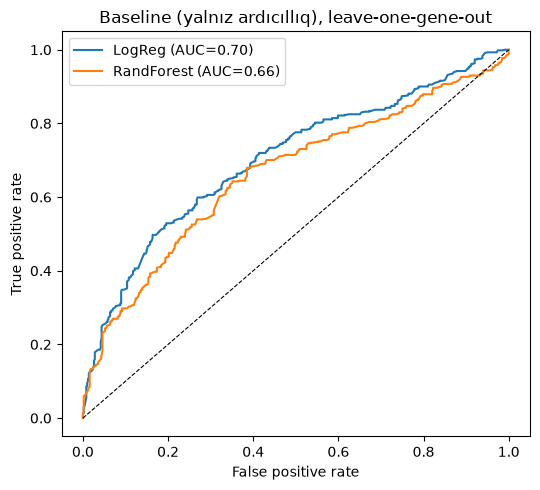

In [53]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(5.5, 5))
for name, p in logo_preds.items():
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, p):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Baseline (yalnız ardıcıllıq), leave-one-gene-out")
plt.legend(); plt.tight_layout()
plt.savefig(BASE / "results/figures/baseline_roc.png", dpi=200)
plt.show()

out = pd.concat([pd.DataFrame(results), pd.DataFrame(within), pd.DataFrame(ref)], ignore_index=True)
out.round(4).to_csv(BASE / "results/tables/baseline_sequence_metrics.csv", index=False)

d.to_csv(BASE / "data/processed/variants_seqfeatures.csv", index=False)

config["notes"].append("Mərhələ 4: ardıcıllıq xüsusiyyətləri (BLOSUM62, hidrofobluq, həcm, yük), baseline LogReg/RF, leave-one-gene-out")
with open(BASE / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)